# Power, MDE, and Sample Size — Analytic and by Simulation

**What you'll learn**

- The four levers of power — sample size, effect size, variance, and $\alpha$ — and how
  to reason about them with one formula (the "rule of 16") before touching any library.
- Analytic sizing with statsmodels for proportions and means, translated into **calendar
  time** with realistic traffic, and why triggering/dilution silently destroys power.
- A generic `simulate_power()` — the tool senior candidates reach for when the metric is
  zero-inflated revenue, the test is Mann–Whitney or a bootstrap, or the design is
  clustered — validated against the analytic answer on the simple case.
- What unequal allocation (90/10) and cluster randomization (geo tests, ICC, design
  effect) really cost, quantified.
- What underpowering does to the results you *do* get: Type M exaggeration (winner's
  curse) and Type S sign errors, measured by simulation.
- One-sided testing and non-inferiority framing, and where each is legitimate.

**Why it matters in interviews**

- "How would you size this experiment?" is *the* experimentation screen for senior DS
  roles. The bar is not plugging numbers into a calculator — it is knowing which lever to
  pull when the answer comes back "14 weeks".
- Case rounds love the constrained variants: "the PM wants an answer in one week",
  "you only get 5% of traffic", "we can only randomize by city". Each has a quantitative
  answer you should be able to sketch on a whiteboard.
- "The test wasn't significant but the lift looks positive — can we ship it?" separates
  candidates who understand Type M/S errors from those who read point estimates.

Design, SRM checks, and the analysis/decision workflow live in
[01_ab_test_end_to_end.ipynb](./01_ab_test_end_to_end.ipynb); this notebook is about what
happens *before* day one: deciding whether the experiment is worth running at all.

In [1]:
import math

import numpy as np
import pandas as pd
import scipy.stats as st
import statsmodels.api as sm
import matplotlib.pyplot as plt
from scipy.optimize import brentq
from statsmodels.stats.power import NormalIndPower, TTestIndPower
from statsmodels.stats.proportion import (
    proportion_confint,
    proportion_effectsize,
    proportions_ztest,
    samplesize_proportions_2indep_onetail,
)

rng = np.random.default_rng(42)

plt.rcParams.update({
    "figure.figsize": (9, 4.5),
    "axes.grid": True,
    "grid.alpha": 0.3,
    "axes.titlesize": 11,
    "figure.constrained_layout.use": True,
})
pd.set_option("display.width", 130)

Z = st.norm  # standard normal, used everywhere


def power_2prop(p0, p1, n_per_arm, alpha=0.05):
    """Normal-approximation power of a two-sided, unpooled two-proportion z-test."""
    delta = np.abs(np.asarray(p1) - np.asarray(p0))
    se = np.sqrt((p0 * (1 - np.asarray(p0)) + p1 * (1 - np.asarray(p1))) / n_per_arm)
    zc = Z.ppf(1 - alpha / 2)
    return Z.cdf(delta / se - zc) + Z.cdf(-delta / se - zc)


def ztest_2prop_counts(x1, n1, x2, n2):
    """Vectorized unpooled two-proportion z-test from counts; two-sided p-values."""
    p1h, p2h = x1 / n1, x2 / n2
    se = np.sqrt(p1h * (1 - p1h) / n1 + p2h * (1 - p2h) / n2)
    z = (p2h - p1h) / se
    return 2 * Z.sf(np.abs(z))

## 1. The four levers of power

For a two-arm test on a difference of means (a proportion is a mean of 0/1s), the
required sample size per arm at significance $\alpha$ (two-sided) and power $1-\beta$ is

$$n_{\text{per arm}} \;=\; \frac{\left(z_{1-\alpha/2} + z_{1-\beta}\right)^2\,
  \left(\sigma_A^2 + \sigma_B^2\right)}{\delta^2},$$

where $\delta$ is the absolute effect you want to detect. With $\alpha=0.05$,
power $=0.8$, and $\sigma_A \approx \sigma_B$, the constant is
$2(1.96+0.84)^2 \approx 15.7$, hence the **rule of 16**:

$$n_{\text{per arm}} \approx 16\,\sigma^2 / \delta^2.$$

Everything in experiment sizing is a corollary of this one formula:

- $n \propto 1/\delta^2$: halving the MDE **quadruples** the sample size.
- $n \propto \sigma^2$: variance is the only lever you can engineer down without
  changing the question — that is the entire business case for CUPED
  ([03_variance_reduction_cuped.ipynb](./03_variance_reduction_cuped.ipynb)).
- The $z$ constant is the *weakest* lever: moving power 80% → 95% multiplies $n$ by
  only $(3.60/2.80)^2 \approx 1.66$, and one-sided $\alpha$ saves ~21% (Section 8).

Equivalently, power at a given $n$ is $\Phi\!\left(\delta/SE - z_{1-\alpha/2}\right)$
(plus a negligible wrong-side tail): a shifted-normal picture worth being able to draw.

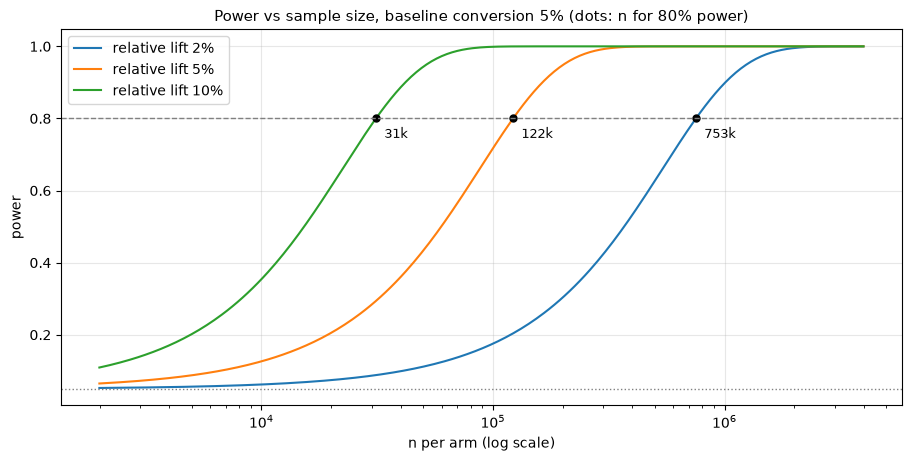

  lift  10%: n/arm for 80% power =    31,233
  lift   5%: n/arm for 80% power =   122,123
  lift   2%: n/arm for 80% power =   752,702
Power 80% -> 95% at the 5% lift: n/arm 122,123 -> 202,188  (x1.66)
As n -> 0 the curves floor at alpha = 0.05: an unpowered test is a coin with P(heads) = alpha.


In [2]:
# Lever 1+2: power vs n for a signup-conversion metric at several relative lifts
p0 = 0.05
ns = np.logspace(3.3, 6.6, 300)

fig, ax = plt.subplots()
for rel in [0.02, 0.05, 0.10]:
    p1 = p0 * (1 + rel)
    ax.plot(ns, power_2prop(p0, p1, ns), label=f"relative lift {rel:.0%}")
    n80 = samplesize_proportions_2indep_onetail(diff=p1 - p0, prop2=p0, power=0.8)
    ax.plot(n80, 0.8, "ko", ms=5)
    ax.annotate(f"{n80/1e3:,.0f}k", (n80, 0.8), textcoords="offset points",
                xytext=(6, -14), fontsize=9)
ax.axhline(0.8, color="gray", ls="--", lw=1)
ax.axhline(0.05, color="gray", ls=":", lw=1)
ax.set(xscale="log", xlabel="n per arm (log scale)", ylabel="power",
       title=f"Power vs sample size, baseline conversion {p0:.0%} (dots: n for 80% power)")
ax.legend()
plt.show()

for rel in [0.10, 0.05, 0.02]:
    n80 = samplesize_proportions_2indep_onetail(diff=p0 * rel, prop2=p0, power=0.8)
    print(f"  lift {rel:>4.0%}: n/arm for 80% power = {n80:>9,.0f}")
n_80 = samplesize_proportions_2indep_onetail(diff=p0 * 0.05, prop2=p0, power=0.8)
n_95 = samplesize_proportions_2indep_onetail(diff=p0 * 0.05, prop2=p0, power=0.95)
print(f"Power 80% -> 95% at the 5% lift: n/arm {n_80:,.0f} -> {n_95:,.0f}  (x{n_95/n_80:.2f})")
print("As n -> 0 the curves floor at alpha = 0.05: an unpowered test is a coin "
      "with P(heads) = alpha.")

The dots make the $1/\delta^2$ law visible: cutting the target lift from 10% to 5%
roughly quadruples the required $n$ (31k → 122k), and 5% to 2% costs another ~6x
(122k → 753k). Note also the flat top — pushing power from 80% to 95% costs only ~66%
more sample, so if a decision is important, 80% is a floor, not a default to worship.

**Lever 3: the baseline rate.** For a *relative* lift, $\delta = \text{rel}\cdot p_0$
grows linearly with the baseline while $\sigma = \sqrt{p_0(1-p_0)}$ grows like
$\sqrt{p_0}$ — so $n \propto (1-p_0)/p_0$. The same 5% relative lift is dramatically
cheaper to detect on a high-rate metric.

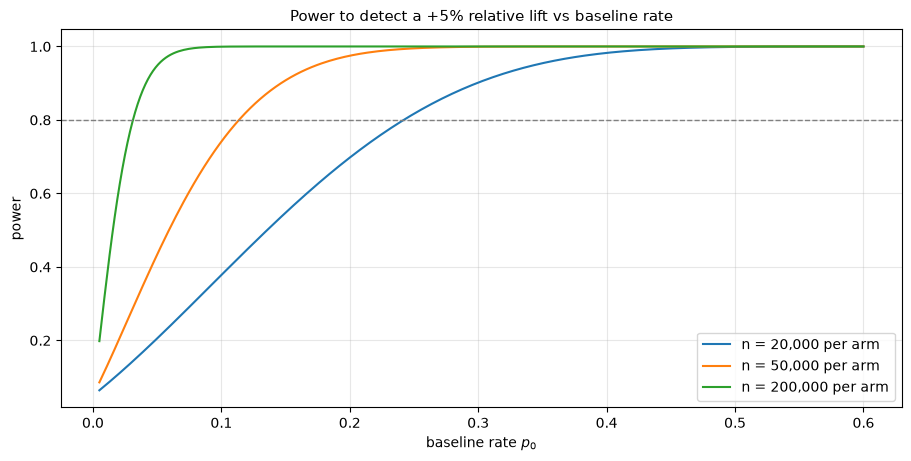

baseline   4%: n/arm for +5% relative =   154,304
baseline  40%: n/arm for +5% relative =     9,492
Same relative lift, ~16x cheaper at the 40% baseline. Metric choice is a power lever: measure the step of the funnel the feature actually moves.


In [3]:
p0_grid = np.linspace(0.005, 0.6, 300)
fig, ax = plt.subplots()
for n_arm in [20_000, 50_000, 200_000]:
    ax.plot(p0_grid, power_2prop(p0_grid, p0_grid * 1.05, n_arm),
            label=f"n = {n_arm:,} per arm")
ax.axhline(0.8, color="gray", ls="--", lw=1)
ax.set(xlabel="baseline rate $p_0$", ylabel="power",
       title="Power to detect a +5% relative lift vs baseline rate")
ax.legend()
plt.show()

for p_base in [0.04, 0.40]:
    n_req = samplesize_proportions_2indep_onetail(diff=p_base * 0.05, prop2=p_base, power=0.8)
    print(f"baseline {p_base:>4.0%}: n/arm for +5% relative = {n_req:>9,.0f}")
print("Same relative lift, ~16x cheaper at the 40% baseline. Metric choice is a power "
      "lever: measure the step of the funnel the feature actually moves.")

**Lever 4: variance — why revenue experiments hurt.** For a mean metric with
coefficient of variation $CV = \sigma/\mu$ and a relative MDE $r$, the rule of 16 reads
$n \approx 16\,CV^2/r^2$: sample size scales with the *square* of the CV.

- A 5% conversion metric has $CV=\sqrt{(1-p)/p}\approx 4.4$.
- Revenue-per-user metrics routinely have $CV$ of 5–10 (mostly zeros plus a heavy
  right tail), so the same relative MDE costs 2–5x more than conversion — before
  worrying about whether a t-test is even valid
  ([../01_statistical_foundations/01_sampling_clt_bootstrap.ipynb](../01_statistical_foundations/01_sampling_clt_bootstrap.ipynb)).

 CV  n_per_arm_for_2pct_rel_MDE
  1                     39244.0
  2                    156978.0
  4                    627910.0
  8                   2511642.0


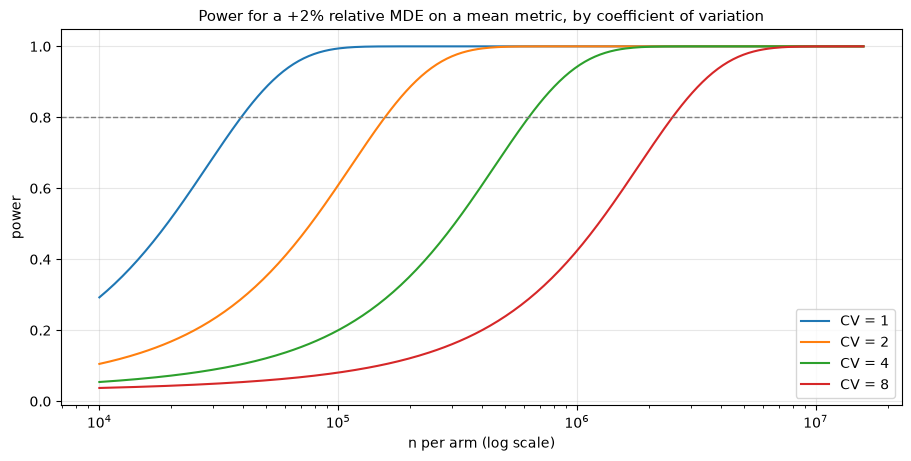

In [4]:
rel_mde = 0.02
z_const = 2 * (Z.ppf(0.975) + Z.ppf(0.8)) ** 2  # ~15.7

rows = []
for cv in [1, 2, 4, 8]:
    rows.append({"CV": cv, "n_per_arm_for_2pct_rel_MDE": z_const * cv**2 / rel_mde**2})
cv_table = pd.DataFrame(rows)
cv_table["n_per_arm_for_2pct_rel_MDE"] = cv_table["n_per_arm_for_2pct_rel_MDE"].round(0)
print(cv_table.to_string(index=False))

ns = np.logspace(4, 7.2, 300)
fig, ax = plt.subplots()
for cv in [1, 2, 4, 8]:
    z_eff = rel_mde * np.sqrt(ns / 2) / cv
    ax.plot(ns, Z.cdf(z_eff - 1.96), label=f"CV = {cv}")
ax.axhline(0.8, color="gray", ls="--", lw=1)
ax.set(xscale="log", xlabel="n per arm (log scale)", ylabel="power",
       title="Power for a +2% relative MDE on a mean metric, by coefficient of variation")
ax.legend()
plt.show()

### MDE is the design lever

In practice you rarely "solve for n" — traffic is what it is. You solve for the
**minimum detectable effect**: the smallest true effect the design would flag with the
target power,
$\text{MDE} = (z_{1-\alpha/2}+z_{1-\beta}) \cdot SE(\hat\delta)$.
The design conversation is then honest: *"with 4 weeks of traffic we can detect a 2%
lift; effects smaller than that will look like noise — is a sub-2% effect worth
shipping anyway?"*

Crucially, the MDE should come from the **smallest effect worth acting on**
(economics: dev cost, risk, opportunity cost of the traffic), not from what you hope
the feature does — and *never* from a pilot's observed effect (Section 9).

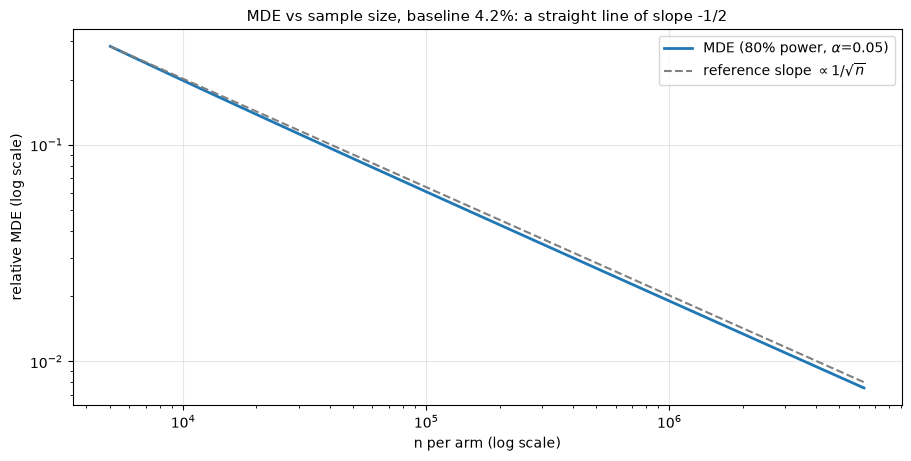

n/arm to detect +3.0% relative:   403,544
n/arm to detect +1.5% relative: 1,602,778   ratio = 3.97
Halving the MDE quadruples the sample size (n ~ 1/MDE^2).


In [5]:
def rel_mde_2prop(n_per_arm, p0, power=0.8, alpha=0.05):
    """Smallest detectable relative lift for a two-proportion test at given n."""
    hi = min(20.0, 0.99 / p0 - 1)
    return brentq(lambda r: power_2prop(p0, p0 * (1 + r), n_per_arm, alpha) - power,
                  1e-6, hi)


p0 = 0.042  # checkout conversion
ns = np.logspace(3.7, 6.8, 40)
mdes = np.array([rel_mde_2prop(n, p0) for n in ns])

fig, ax = plt.subplots()
ax.loglog(ns, mdes, lw=2, label="MDE (80% power, $\\alpha$=0.05)")
ax.loglog(ns, mdes[0] * np.sqrt(ns[0] / ns), "--", color="gray",
          label="reference slope $\\propto 1/\\sqrt{n}$")
ax.set(xlabel="n per arm (log scale)", ylabel="relative MDE (log scale)",
       title=f"MDE vs sample size, baseline {p0:.1%}: a straight line of slope -1/2")
ax.legend()
plt.show()

n_3pct = samplesize_proportions_2indep_onetail(diff=p0 * 0.03, prop2=p0, power=0.8)
n_15pct = samplesize_proportions_2indep_onetail(diff=p0 * 0.015, prop2=p0, power=0.8)
print(f"n/arm to detect +3.0% relative: {n_3pct:>9,.0f}")
print(f"n/arm to detect +1.5% relative: {n_15pct:>9,.0f}   ratio = {n_15pct/n_3pct:.2f}")
print("Halving the MDE quadruples the sample size (n ~ 1/MDE^2).")

## 2. Analytic sizing with statsmodels, and calendar time

For proportions and plain means the analytic machinery is all you need. Three ways to
get the same number for a conversion metric — statsmodels' effect-size route, its
direct two-proportion routine, and the rule of 16:

In [6]:
p0 = 0.042
rel = 0.03
p1 = p0 * (1 + rel)

h = proportion_effectsize(p1, p0)  # Cohen's h (arcsine scale)
n_h = NormalIndPower().solve_power(effect_size=h, power=0.8, alpha=0.05)
n_direct = samplesize_proportions_2indep_onetail(diff=p1 - p0, prop2=p0, power=0.8)
pbar = (p0 + p1) / 2
n_rule16 = 16 * pbar * (1 - pbar) / (p1 - p0) ** 2

print(f"Detect +3% relative on a 4.2% baseline (p1 = {p1:.4f}), alpha=0.05, power=0.8:")
print(f"  NormalIndPower via Cohen's h        : n/arm = {n_h:>9,.0f}")
print(f"  samplesize_proportions_2indep       : n/arm = {n_direct:>9,.0f}")
print(f"  rule of 16 (16*p(1-p)/delta^2)      : n/arm = {n_rule16:>9,.0f}")
print("All within a few percent - the back-of-envelope answer is interview-grade.")

Detect +3% relative on a 4.2% baseline (p1 = 0.0433), alpha=0.05, power=0.8:
  NormalIndPower via Cohen's h        : n/arm =   403,522
  samplesize_proportions_2indep       : n/arm =   403,544
  rule of 16 (16*p(1-p)/delta^2)      : n/arm =   411,315
All within a few percent - the back-of-envelope answer is interview-grade.


In [7]:
# A mean metric: ARPU (average revenue per user), heavy-tailed as usual
arpu_mean, arpu_sd = 3.40, 24.0        # CV ~ 7 - typical for revenue per user
delta = 0.02 * arpu_mean               # +2% relative MDE

d = delta / arpu_sd                    # Cohen's d
n_arpu = TTestIndPower().solve_power(effect_size=d, power=0.8, alpha=0.05)
print(f"ARPU test, +2% relative MDE (Cohen's d = {d:.5f}):")
print(f"  n/arm = {n_arpu:,.0f}  ({2*n_arpu/1e6:.1f}M users total)")
print(f"  With CUPED at rho = 0.7, variance shrinks by 1-rho^2 = {1-0.7**2:.2f} "
      f"-> n/arm = {n_arpu*(1-0.7**2):,.0f}")
print("Variance reduction is not a nice-to-have for revenue metrics; it is the "
      "difference between 8 weeks and 4 (see 03_variance_reduction_cuped.ipynb).")

ARPU test, +2% relative MDE (Cohen's d = 0.00283):
  n/arm = 1,955,426  (3.9M users total)
  With CUPED at rho = 0.7, variance shrinks by 1-rho^2 = 0.51 -> n/arm = 997,267
Variance reduction is not a nice-to-have for revenue metrics; it is the difference between 8 weeks and 4 (see 03_variance_reduction_cuped.ipynb).


### Duration planning: n is not the deliverable, weeks are

Stakeholders don't experience sample sizes, they experience calendar time. Suppose the
checkout experiment can enroll **540,000 eligible users per week**, split 50/50. Two
practical rules on top of the arithmetic:

- Run **whole weeks** (at least 2): day-of-week mix and novelty effects make partial
  weeks unrepresentative — see [01_ab_test_end_to_end.ipynb](./01_ab_test_end_to_end.ipynb).
- If the honest answer is "14 weeks", the design is wrong, not the calendar: change the
  metric (higher baseline / lower CV), reduce variance, or accept a larger MDE.

In [8]:
WEEKLY_ELIGIBLE = 540_000
weekly_per_arm = WEEKLY_ELIGIBLE // 2

rows = []
for rel in [0.01, 0.02, 0.03, 0.05, 0.10]:
    n_arm = samplesize_proportions_2indep_onetail(diff=p0 * rel, prop2=p0, power=0.8)
    weeks = max(2, math.ceil(n_arm / weekly_per_arm))
    rows.append({"relative_MDE": f"{rel:.0%}", "n_per_arm": round(n_arm),
                 "total_n": round(2 * n_arm), "weeks (min 2)": weeks})
duration = pd.DataFrame(rows)
print(f"Baseline conversion {p0:.1%}, {WEEKLY_ELIGIBLE:,} eligible users/week, 50/50 split:")
print(duration.to_string(index=False))

Baseline conversion 4.2%, 540,000 eligible users/week, 50/50 split:
relative_MDE  n_per_arm  total_n  weeks (min 2)
          1%    3597697  7195394             14
          2%     903700  1807400              4
          3%     403544   807087              2
          5%     146642   293284              2
         10%      37513    75025              2


## 3. Triggering and dilution: only affected users should count

The single most common sizing mistake in industry: powering (and analyzing) on **all
randomized users** when the feature can only affect a subset. Say a new checkout flow
is only seen by users who *reach* checkout — 25% of eligible users ("trigger rate"
$\tau = 0.25$). Among triggered users the metric is purchase conversion, baseline 60%.

If you analyze all users, the absolute effect is diluted by $\tau$
($\delta_{\text{all}} = \tau\,\delta_{\text{trig}}$) while the variance does **not**
shrink by $\tau^2$ — so power collapses. Worse, any conversions that happen through
paths the feature cannot touch (say a legacy one-click flow used by non-triggered
users) add variance with zero signal, diluting further.

In [9]:
tau = 0.25            # share of eligible users who reach checkout (triggered)
p_trig0 = 0.60        # purchase conversion among triggered, control
lift_trig = 0.02      # +2% relative among triggered
p_trig1 = p_trig0 * (1 + lift_trig)
p_legacy = 0.10       # non-triggered users still buy via a legacy flow

# Strategy 1: analyze triggered users only (need n_trig per arm, exposure = n_trig/tau)
n_trig = samplesize_proportions_2indep_onetail(diff=p_trig1 - p_trig0, prop2=p_trig0, power=0.8)
exposure_trig = n_trig / tau

# Strategy 2: analyze all users, purchases only possible via checkout
p_all0 = tau * p_trig0
p_all1 = tau * p_trig1
n_all_clean = samplesize_proportions_2indep_onetail(diff=p_all1 - p_all0, prop2=p_all0, power=0.8)

# Strategy 3: analyze all users, non-triggered also buy via legacy flow (extra noise)
p_all0_leg = tau * p_trig0 + (1 - tau) * p_legacy
p_all1_leg = tau * p_trig1 + (1 - tau) * p_legacy
n_all_leg = samplesize_proportions_2indep_onetail(diff=p_all1_leg - p_all0_leg,
                                                  prop2=p_all0_leg, power=0.8)

dil = pd.DataFrame([
    {"analysis": "triggered only",           "baseline": p_trig0,   "abs_effect": p_trig1 - p_trig0,
     "eligible_needed_per_arm": exposure_trig},
    {"analysis": "all users (no legacy)",    "baseline": p_all0,    "abs_effect": p_all1 - p_all0,
     "eligible_needed_per_arm": n_all_clean},
    {"analysis": "all users (+legacy noise)", "baseline": p_all0_leg, "abs_effect": p_all1_leg - p_all0_leg,
     "eligible_needed_per_arm": n_all_leg},
])
dil["eligible_needed_per_arm"] = dil["eligible_needed_per_arm"].round(0)
dil["x_vs_triggered"] = (dil["eligible_needed_per_arm"] / exposure_trig).round(2)
print(f"Trigger rate tau = {tau:.0%}; +2% relative lift among triggered users:")
print(dil.to_string(index=False))

Trigger rate tau = 25%; +2% relative lift among triggered users:
                 analysis  baseline  abs_effect  eligible_needed_per_arm  x_vs_triggered
           triggered only     0.600       0.012                 104108.0            1.00
    all users (no legacy)     0.150       0.003                 224211.0            2.15
all users (+legacy noise)     0.225       0.003                 305578.0            2.94


In [10]:
# Same story as achieved power at a FIXED budget of 110k eligible users per arm
N_ELIG = 110_000
n_sims = 4000

nt_c = rng.binomial(N_ELIG, tau, n_sims)          # triggered counts per sim
nt_t = rng.binomial(N_ELIG, tau, n_sims)
conv_c = rng.binomial(nt_c, p_trig0)              # checkout purchases
conv_t = rng.binomial(nt_t, p_trig1)
leg_c = rng.binomial(N_ELIG - nt_c, p_legacy)     # legacy purchases (unaffected)
leg_t = rng.binomial(N_ELIG - nt_t, p_legacy)

p_triggered = ztest_2prop_counts(conv_c, nt_c, conv_t, nt_t)
p_allusers = ztest_2prop_counts(conv_c + leg_c, N_ELIG, conv_t + leg_t, N_ELIG)

print(f"Fixed budget of {N_ELIG:,} eligible users per arm ({n_sims:,} simulated experiments):")
print(f"  power, triggered-only analysis : {(p_triggered < 0.05).mean():.3f}")
print(f"  power, all-user analysis       : {(p_allusers  < 0.05).mean():.3f}")
print("Identical experiment, identical traffic - the denominator choice alone "
      "decides whether it is powered.")

Fixed budget of 110,000 eligible users per arm (4,000 simulated experiments):
  power, triggered-only analysis : 0.816
  power, all-user analysis       : 0.382
Identical experiment, identical traffic - the denominator choice alone decides whether it is powered.


Same users, same feature, same true effect: analyzing the diluted all-user metric
roughly **triples** the traffic requirement here, and at a fixed budget turns an
~80%-powered test into a ~40% one.

Two caveats that interviewers probe:

- **Triggering must be treatment-independent.** Condition only on behavior that happens
  *before* the experiences diverge (reaching checkout), or on counterfactual triggering
  ("would this user have seen the change?"). Conditioning on post-treatment behavior is
  selection bias — the "bad controls" trap from
  [../03_causal_inference/01_potential_outcomes_dags.ipynb](../03_causal_inference/01_potential_outcomes_dags.ipynb).
- Run SRM checks on the *triggered* population too; a triggering bug that fires
  differentially by arm looks exactly like a treatment effect
  ([01_ab_test_end_to_end.ipynb](./01_ab_test_end_to_end.ipynb)).

## 4. `simulate_power()`: the senior tool

Analytic power formulas assume: the estimator is a difference of independent means, the
sampling distribution is normal, and the test is the matching z/t-test. Real designs
violate at least one: zero-inflated revenue metrics, Mann–Whitney or bootstrap tests,
capped/winsorized metrics, clustered randomization, triggered subsets, unequal
allocation, sequential looks.

The general recipe never changes:

1. Write a generator that simulates **one whole experiment** under your assumed truth.
2. Run the **exact analysis you will actually run** on each simulated experiment.
3. Power = fraction of simulations that reject. (Run it with zero effect too — you get
   the realized false-positive rate of the whole pipeline for free.)

Rule of craft: **validate the harness on a case with a known analytic answer first.**
If your simulator can't reproduce the two-proportion answer, it has a bug; only then
point it at the weird stuff.

In [11]:
def simulate_power(draw_experiment, test_pvalue, n_sims=500, alpha=0.05, seed=0):
    """Generic simulation-based power.

    draw_experiment(rng) -> tuple of arguments for test_pvalue
    test_pvalue(*args)   -> two-sided p-value for one experiment
    Returns (power, wilson_lo, wilson_hi).
    """
    rng_sim = np.random.default_rng(seed)
    hits = sum(test_pvalue(*draw_experiment(rng_sim)) < alpha for _ in range(n_sims))
    lo, hi = proportion_confint(hits, n_sims, method="wilson")
    return hits / n_sims, lo, hi


def two_arm(sample_control, sample_treat, n_control, n_treat=None):
    """Standard two-arm design: draw (control, treatment) samples."""
    n_treat = n_control if n_treat is None else n_treat

    def draw(rng):
        return sample_control(n_control, rng), sample_treat(n_treat, rng)

    return draw


def bernoulli(p):
    def sample(n, rng):
        return (rng.random(n) < p).astype(np.int8)
    return sample


def ztest_binary(x, y):
    stat, pval = proportions_ztest([x.sum(), y.sum()], [x.size, y.size])
    return pval

In [12]:
# Validation: does the simulator reproduce the analytic two-proportion answer?
p0, p1 = 0.25, 0.26
n_arm = math.ceil(samplesize_proportions_2indep_onetail(diff=p1 - p0, prop2=p0, power=0.8))
analytic = power_2prop(p0, p1, n_arm)

pw, lo, hi = simulate_power(two_arm(bernoulli(p0), bernoulli(p1), n_arm),
                            ztest_binary, n_sims=1000, seed=7)
print(f"Two-proportion test, {p0:.0%} -> {p1:.0%}, n = {n_arm:,}/arm")
print(f"  analytic power : {analytic:.3f}")
print(f"  simulated power: {pw:.3f}  (95% CI [{lo:.3f}, {hi:.3f}], 1000 sims)")

pw0, lo0, hi0 = simulate_power(two_arm(bernoulli(p0), bernoulli(p0), n_arm),
                               ztest_binary, n_sims=1000, seed=8)
print(f"  A/A false-positive rate: {pw0:.3f}  (95% CI [{lo0:.3f}, {hi0:.3f}]) - should be ~0.05")

Two-proportion test, 25% -> 26%, n = 29,821/arm
  analytic power : 0.800
  simulated power: 0.791  (95% CI [0.765, 0.815], 1000 sims)


  A/A false-positive rate: 0.050  (95% CI [0.038, 0.065]) - should be ~0.05


### Revenue with zeros: same ARPU lift, very different detectability

Now the metric analytic formulas can't handle honestly: **revenue per user** on an
upsell surface — 75% zeros, lognormal spend among payers. Two treatments with the
*identical* +10% ARPU impact:

- **Scenario A — more payers**: payer rate 25% → 27.5%, spend distribution unchanged.
- **Scenario B — payers spend more**: payer rate unchanged, spend per payer +10%
  (a multiplicative shift, i.e. the effect lives in the heavy tail).

We measure the power of three analyses at the same $n$, on the *same simulated
datasets* (same seed → paired comparison):
Welch's t on raw revenue, Mann–Whitney, and a percentile-bootstrap test of the
difference in means.

Control revenue/user: ARPU = 8.31, share zero = 75.0%, CV = 3.22, p99 = 117


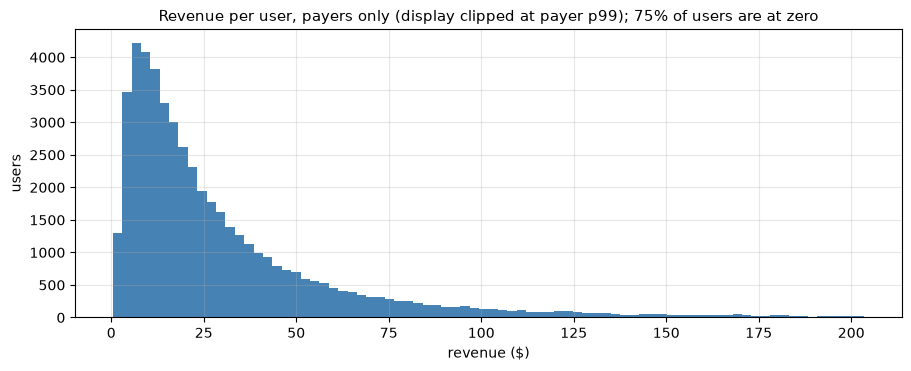

In [13]:
PAY0, MU0, SIG0 = 0.25, 3.0, 1.0


def revenue_sampler(pay_rate, mu):
    def sample(n, rng):
        rev = np.zeros(n)
        payers = rng.random(n) < pay_rate
        rev[payers] = rng.lognormal(mu, SIG0, payers.sum())
        return rev
    return sample


preview = revenue_sampler(PAY0, MU0)(200_000, rng)
print(f"Control revenue/user: ARPU = {preview.mean():.2f}, share zero = {(preview == 0).mean():.1%}, "
      f"CV = {preview.std()/preview.mean():.2f}, p99 = {np.quantile(preview, 0.99):.0f}")

fig, ax = plt.subplots(figsize=(9, 3.6))
pos = preview[preview > 0]
ax.hist(pos[pos < np.quantile(pos, 0.99)], bins=80, color="steelblue")
ax.set(title="Revenue per user, payers only (display clipped at payer p99); 75% of users are at zero",
       xlabel="revenue ($)", ylabel="users")
plt.show()

In [14]:
_BOOT_RNG = np.random.default_rng(2024)  # test-internal randomness, seeded once


def bootstrap_meandiff_pvalue(x, y, n_boot=200):
    """CI-inversion p-value from a percentile bootstrap of mean(y) - mean(x)."""
    ix = _BOOT_RNG.integers(0, x.size, size=(n_boot, x.size))
    iy = _BOOT_RNG.integers(0, y.size, size=(n_boot, y.size))
    diffs = y[iy].mean(axis=1) - x[ix].mean(axis=1)
    p_two = 2 * min((diffs <= 0).mean(), (diffs >= 0).mean())
    return max(p_two, 1 / n_boot)


tests = {
    "Welch t (mean)": lambda x, y: st.ttest_ind(x, y, equal_var=False).pvalue,
    "Mann-Whitney": lambda x, y: st.mannwhitneyu(x, y, alternative="two-sided").pvalue,
    "bootstrap mean": bootstrap_meandiff_pvalue,
}
scenarios = {
    "null (A/A)": (PAY0, MU0),
    "A: +10% payer rate": (PAY0 * 1.10, MU0),
    "B: +10% spend/payer": (PAY0, MU0 + np.log(1.10)),
}

N_ARM_REV, N_SIMS_REV = 5000, 250
cells = {}
for sc_name, (pay, mu) in scenarios.items():
    draw = two_arm(revenue_sampler(PAY0, MU0), revenue_sampler(pay, mu), N_ARM_REV)
    for t_name, t_fn in tests.items():
        pw, lo, hi = simulate_power(draw, t_fn, n_sims=N_SIMS_REV, seed=11)
        cells[(sc_name, t_name)] = f"{pw:.2f} [{lo:.2f}, {hi:.2f}]"

power_table = pd.Series(cells).unstack().reindex(index=list(scenarios), columns=list(tests))
print(f"Simulated power, n = {N_ARM_REV:,}/arm, {N_SIMS_REV} sims/cell (identical data across tests):")
print(power_table.to_string())

Simulated power, n = 5,000/arm, 250 sims/cell (identical data across tests):
                        Welch t (mean)       Mann-Whitney     bootstrap mean
null (A/A)           0.04 [0.02, 0.08]  0.05 [0.03, 0.08]  0.04 [0.02, 0.08]
A: +10% payer rate   0.38 [0.32, 0.44]  0.79 [0.73, 0.83]  0.37 [0.31, 0.43]
B: +10% spend/payer  0.31 [0.26, 0.37]  0.07 [0.04, 0.11]  0.30 [0.25, 0.36]


Read the table row by row — it is one of the highest-yield results in this notebook:

- **Null row**: all three tests hold their size near 5%. Cheap insurance, always run it.
- **Scenario A (more payers)**: Mann–Whitney is *far* more powerful than the t-test.
  The effect is a mass shift from zero to positive — exactly the stochastic-dominance
  signal MW is built for — while the t-test drowns it in whale variance.
- **Scenario B (payers spend more)**: the ranking flips *hard*. MW is nearly blind
  (~α-level power!) because a 10% multiplicative shift barely moves ranks when only 25%
  of users have nonzero values, while the mean moves just as much as in A.
- The bootstrap tracks Welch: they estimate the same thing (the mean).

The senior lesson: **power depends on the test–effect pairing, not the test alone** —
and "Mann–Whitney is significant" does not mean revenue moved. If the business decision
is about total revenue, the estimand is the mean; test that (with variance-reduction
help), and treat MW as answering a different question — see
[../01_statistical_foundations/02_hypothesis_testing_beyond_basics.ipynb](../01_statistical_foundations/02_hypothesis_testing_beyond_basics.ipynb).

## 5. Unequal allocation: what 90/10 costs

$\text{Var}(\hat\delta) = \sigma^2\,(1/n_T + 1/n_C)$. At fixed total $N$ with treatment
share $q$, that is $\sigma^2/\big(N q(1-q)\big)$ — minimized at 50/50. The cost of an
unbalanced split is the **total-N multiplier** $\;0.25/\big(q(1-q)\big)$ to reach the
same power:

 treatment_share  SE_multiplier_vs_5050  total_N_multiplier
            0.50                   1.00                1.00
            0.70                   1.09                1.19
            0.80                   1.25                1.56
            0.90                   1.67                2.78
            0.95                   2.29                5.26
            0.99                   5.03               25.25


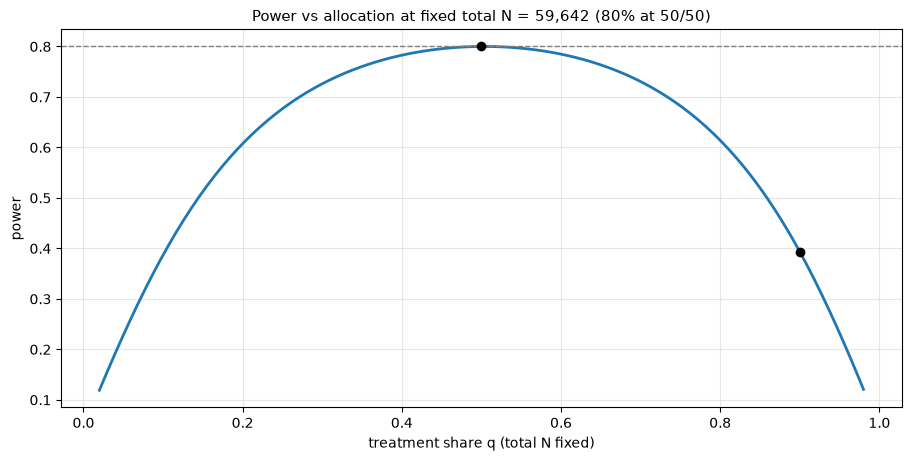

90/10 split of the same total N: analytic power = 0.39, simulated = 0.37 [0.35, 0.40]


In [15]:
shares = np.array([0.50, 0.70, 0.80, 0.90, 0.95, 0.99])
alloc = pd.DataFrame({
    "treatment_share": shares,
    "SE_multiplier_vs_5050": np.sqrt(0.25 / (shares * (1 - shares))).round(2),
    "total_N_multiplier": (0.25 / (shares * (1 - shares))).round(2),
})
print(alloc.to_string(index=False))

p0, p1 = 0.25, 0.26
N_total = 2 * n_arm  # from the Section 4 validation: 80% power at 50/50

q_grid = np.linspace(0.02, 0.98, 200)
se_q = np.sqrt(p0 * (1 - p0) / ((1 - q_grid) * N_total) + p1 * (1 - p1) / (q_grid * N_total))
power_q = Z.cdf((p1 - p0) / se_q - 1.96)

fig, ax = plt.subplots()
ax.plot(q_grid, power_q, lw=2)
ax.axhline(0.8, color="gray", ls="--", lw=1)
for q_mark in [0.5, 0.9]:
    se_m = np.sqrt(p0*(1-p0)/((1-q_mark)*N_total) + p1*(1-p1)/(q_mark*N_total))
    ax.plot(q_mark, Z.cdf((p1-p0)/se_m - 1.96), "ko")
ax.set(xlabel="treatment share q (total N fixed)", ylabel="power",
       title=f"Power vs allocation at fixed total N = {N_total:,} (80% at 50/50)")
plt.show()

# Simulation spot-check of the 90/10 point with the generic harness
n_t, n_c = round(0.1 * N_total), round(0.9 * N_total)
pw_9010, lo_, hi_ = simulate_power(two_arm(bernoulli(p0), bernoulli(p1), n_c, n_t),
                                   ztest_binary, n_sims=1200, seed=21)
se_9010 = np.sqrt(p0*(1-p0)/n_c + p1*(1-p1)/n_t)
print(f"90/10 split of the same total N: analytic power = {Z.cdf((p1-p0)/se_9010 - 1.96):.2f}, "
      f"simulated = {pw_9010:.2f} [{lo_:.2f}, {hi_:.2f}]")

Notice the flat top: 60/40 or 70/30 costs almost nothing (x1.04–x1.19 total N), while
95/5 needs >5x the total sample. Two follow-ups a senior candidate should know:

- **When the treatment arm is capped** (risky rollout, costly treatment), the question
  becomes: how much control is worth adding? SE $\propto \sqrt{1 + 1/k}$ where
  $k = n_C/n_T$ — the marginal value of control decays fast.
- **Neyman allocation**: with unequal variances, the optimal split is
  $n_T/n_C = \sigma_T/\sigma_C$ — relevant when treatment adds variance (new payment
  flow with a new spend distribution).

In [16]:
n_t_fixed = 8000
k_grid = np.array([0.5, 1, 2, 3, 4, 6, 9, 15, 30])
se_k = np.sqrt(p0*(1-p0)/(k_grid*n_t_fixed) + p1*(1-p1)/n_t_fixed)
se_inf = np.sqrt(p1*(1-p1)/n_t_fixed)

ctrl = pd.DataFrame({
    "control_multiple_k": k_grid,
    "power": Z.cdf((p1-p0)/se_k - 1.96).round(3),
    "MDE_inflation_vs_infinite_control": (se_k / se_inf).round(3),
})
print(f"Treatment arm fixed at {n_t_fixed:,} users ({p0:.0%} -> {p1:.0%}):")
print(ctrl.to_string(index=False))
print("Control at 3-4x treatment already captures most of the value; beyond ~9x is noise.")

Treatment arm fixed at 8,000 users (25% -> 26%):
 control_multiple_k  power  MDE_inflation_vs_infinite_control
                0.5  0.220                              1.717
                1.0  0.305                              1.405
                2.0  0.387                              1.220
                3.0  0.425                              1.151
                4.0  0.448                              1.115
                6.0  0.473                              1.078
                9.0  0.491                              1.053
               15.0  0.506                              1.032
               30.0  0.519                              1.016
Control at 3-4x treatment already captures most of the value; beyond ~9x is noise.


**When 90/10 is right anyway** — allocation is a business decision, not just a variance
one:

- *Blast-radius control*: a risky infra or pricing change where downside exposure must
  be capped; you pay in duration to buy insurance.
- *Costly treatment*: human-in-the-loop review, GPU-heavy models, paid incentives.
- *Shared control*: many concurrent treatments compared against one large control uses
  traffic far more efficiently than pairwise 50/50s.
- *Long-term holdouts*: a 5% global holdout measures cumulative impact for quarters.

Remember that the SRM check must test against the *designed* ratio
([01_ab_test_end_to_end.ipynb](./01_ab_test_end_to_end.ipynb)).

## 6. Cluster randomization: ICC and the design effect

When you randomize **groups** (cities/geos, stores, sales teams, classrooms) instead of
users — usually to dodge interference
([06_advanced_designs_interference.ipynb](./06_advanced_designs_interference.ipynb)) —
users within a cluster are correlated. With $m$ users per cluster and intraclass
correlation $\rho$, the variance of the estimate inflates by the **design effect**

$$\text{DEFF} = 1 + (m - 1)\,\rho ,$$

so the *effective* sample size is $N/\text{DEFF}$. The killer is that $m$ is huge in geo
tests: even a tiny $\rho$ becomes a massive DEFF because geos genuinely differ
(urban/rural mix, income, seasonality).

Setup: 40 geos, 3,000 users each (120k users), baseline conversion 10% with
between-geo SD of 2.5pp, and a **+5% relative** treatment lift. We compare the correct
geo-level analysis against user-level randomization, and show what happens if you
(wrongly) analyze geo-randomized data at the user level.

In [17]:
N_GEOS, M_USERS = 40, 3000
BASE_P, GEO_SD, GEO_LIFT = 0.10, 0.025, 0.05

icc = GEO_SD**2 / (GEO_SD**2 + BASE_P * (1 - BASE_P))
deff = 1 + (M_USERS - 1) * icc
n_total = N_GEOS * M_USERS
print(f"ICC = {icc:.4f}  ->  DEFF = 1 + (m-1)*ICC = {deff:.1f}")
print(f"{n_total:,} users are worth {n_total/deff:,.0f} independent users "
      f"({n_total/deff/2:,.0f} per arm).")


def geo_experiment(lift):
    """One geo-randomized experiment: returns (conversions_per_geo, treated_mask, m)."""
    def draw(rng):
        p_g = np.clip(rng.normal(BASE_P, GEO_SD, N_GEOS), 0.005, 0.6)
        treated = np.zeros(N_GEOS, dtype=bool)
        treated[rng.permutation(N_GEOS)[: N_GEOS // 2]] = True
        p_eff = np.where(treated, p_g * (1 + lift), p_g)
        return rng.binomial(M_USERS, p_eff), treated, M_USERS
    return draw


def geo_level_ttest(conv, treated, m):
    """Correct analysis: t-test on geo-level conversion rates (n = number of geos)."""
    rates = conv / m
    return st.ttest_ind(rates[treated], rates[~treated], equal_var=False).pvalue


def user_level_ztest(conv, treated, m):
    """WRONG analysis: pool users and pretend they were individually randomized."""
    return float(ztest_2prop_counts(conv[~treated].sum(), (~treated).sum() * m,
                                    conv[treated].sum(), treated.sum() * m))

ICC = 0.0069  ->  DEFF = 1 + (m-1)*ICC = 21.7
120,000 users are worth 5,534 independent users (2,767 per arm).


In [18]:
pw_geo, lo1, hi1 = simulate_power(geo_experiment(GEO_LIFT), geo_level_ttest, n_sims=1000, seed=31)
size_geo, lo2, hi2 = simulate_power(geo_experiment(0.0), geo_level_ttest, n_sims=1000, seed=32)
fpr_naive, lo3, hi3 = simulate_power(geo_experiment(0.0), user_level_ztest, n_sims=1000, seed=33)
pw_user_rand = power_2prop(BASE_P, BASE_P * (1 + GEO_LIFT), n_total // 2)

summary = pd.DataFrame([
    {"design/analysis": "user-randomized, user-level test (same 120k users)",
     "true effect": "+5% rel", "rejection rate": f"{pw_user_rand:.2f} (analytic)"},
    {"design/analysis": "geo-randomized, geo-level t-test (correct)",
     "true effect": "+5% rel", "rejection rate": f"{pw_geo:.2f} [{lo1:.2f}, {hi1:.2f}]"},
    {"design/analysis": "geo-randomized, geo-level t-test (correct)",
     "true effect": "none", "rejection rate": f"{size_geo:.2f} [{lo2:.2f}, {hi2:.2f}]"},
    {"design/analysis": "geo-randomized, user-level z-test (WRONG)",
     "true effect": "none", "rejection rate": f"{fpr_naive:.2f} [{lo3:.2f}, {hi3:.2f}]"},
])
print(summary.to_string(index=False))

se_geo = np.sqrt(2 * (GEO_SD**2 + BASE_P * (1 - BASE_P) / M_USERS) / (N_GEOS // 2))
mde_geo = (1.96 + Z.ppf(0.8)) * se_geo
geos_needed = 2 * math.ceil(2 * (GEO_SD**2 + BASE_P*(1-BASE_P)/M_USERS) /
                            (GEO_LIFT * BASE_P / (1.96 + Z.ppf(0.8)))**2)
print(f"\nGeo-level MDE with {N_GEOS} geos: {mde_geo:.4f} absolute = "
      f"{mde_geo/BASE_P:.0%} relative(!)")
print(f"Geos needed for 80% power at +5% relative: ~{geos_needed:,} - more than exist.")

                                   design/analysis true effect    rejection rate
user-randomized, user-level test (same 120k users)     +5% rel   0.81 (analytic)
        geo-randomized, geo-level t-test (correct)     +5% rel 0.09 [0.07, 0.11]
        geo-randomized, geo-level t-test (correct)        none 0.06 [0.05, 0.08]
         geo-randomized, user-level z-test (WRONG)        none 0.66 [0.63, 0.69]

Geo-level MDE with 40 geos: 0.0227 absolute = 23% relative(!)
Geos needed for 80% power at +5% relative: ~824 - more than exist.


Three facts to internalize from that table:

- **The power collapse is total**: the same 120k users deliver ~80% power under
  user-level randomization but only ~10% under geo randomization. The unit of
  randomization, not the number of users, sets the power.
- **The naive user-level read of a geo test is catastrophic**: with *zero* true effect
  it "finds" a significant result in roughly two-thirds of experiments, because the
  z-test's independence assumption is off by a factor of DEFF ≈ 22. This is the same
  clustered-SE story as
  [05_ratio_metrics_delta_method.ipynb](./05_ratio_metrics_delta_method.ipynb).
- **You cannot buy your way out with users** — only with *clusters* or with variance
  reduction *between* clusters: pairing/stratifying geos, pre-period covariate
  adjustment (Exercise 3 shows it rescues this exact design), or synthetic-control-style
  analyses ([../03_causal_inference/03_did_synthetic_control.ipynb](../03_causal_inference/03_did_synthetic_control.ipynb)).

## 7. What underpowering does to the results you get

Suppose the true lift is small but real, and the test is underpowered. Conditioning on
significance (which is what "we only ship winners" does) produces two systematic
errors, in Gelman & Carlin's terms:

- **Type M (magnitude)**: among significant results, the estimated effect is *inflated*
  — you had to be lucky to clear the significance bar, so the lucky draws are what you
  see. This is the winner's curse behind "our shipped wins don't add up in the annual
  numbers" (regression to the mean:
  [../01_statistical_foundations/04_statistical_traps.ipynb](../01_statistical_foundations/04_statistical_traps.ipynb)).
- **Type S (sign)**: some significant results have the *wrong sign* — you confidently
  ship a harmful change.

True effect below: **+2% relative** on a 10% conversion baseline; we vary $n$ to sweep
design power and measure both errors among significant results.

In [19]:
P0_MS, REL_MS = 0.10, 0.02
P1_MS = P0_MS * (1 + REL_MS)
DELTA_MS = P1_MS - P0_MS
N_SIMS_MS = 30_000

rows = []
for target in [0.10, 0.15, 0.20, 0.30, 0.50, 0.80, 0.90]:
    n = math.ceil(samplesize_proportions_2indep_onetail(diff=DELTA_MS, prop2=P0_MS,
                                                        power=target))
    x = rng.binomial(n, P0_MS, N_SIMS_MS)
    y = rng.binomial(n, P1_MS, N_SIMS_MS)
    est = y / n - x / n
    se = np.sqrt((x/n)*(1-x/n)/n + (y/n)*(1-y/n)/n)
    sig = np.abs(est / se) > 1.96
    rows.append({
        "design_power": target,
        "n_per_arm": n,
        "sim_power": sig.mean(),
        "exaggeration_x (E|est|/true | sig)": np.abs(est[sig]).mean() / DELTA_MS,
        "sign_error_% (est<0 | sig)": 100 * (est[sig] < 0).mean(),
    })
ms = pd.DataFrame(rows).round({"sim_power": 3, "exaggeration_x (E|est|/true | sig)": 2,
                               "sign_error_% (est<0 | sig)": 2})
print(f"True effect: +{REL_MS:.0%} relative ({DELTA_MS:.4f} absolute) on {P0_MS:.0%} baseline")
print(ms.to_string(index=False))

True effect: +2% relative (0.0020 absolute) on 10% baseline
 design_power  n_per_arm  sim_power  exaggeration_x (E|est|/true | sig)  sign_error_% (est<0 | sig)
         0.10      20896      0.103                                3.58                        3.76
         0.15      38723      0.149                                2.67                        1.23
         0.20      56782      0.195                                2.25                        0.50
         0.30      93562      0.304                                1.81                        0.09
         0.50     174401      0.495                                1.41                        0.01
         0.80     356335      0.801                                1.12                        0.00
         0.90     477030      0.901                                1.06                        0.00


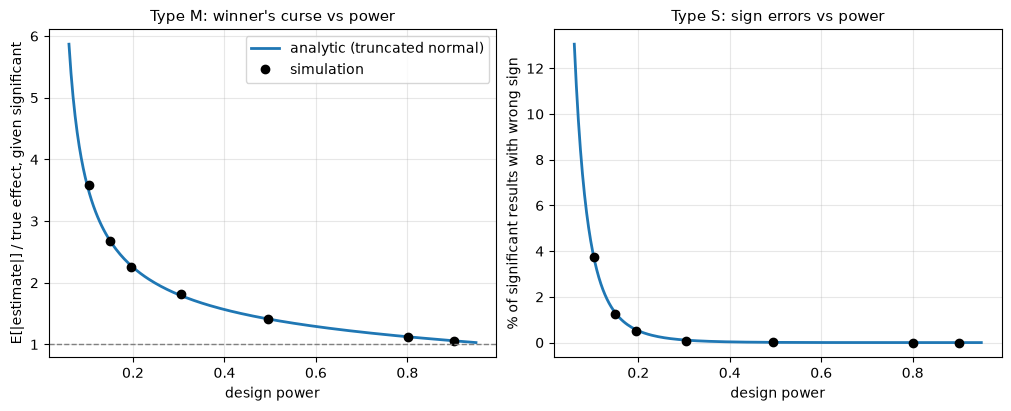

In [20]:
# Analytic overlay: truncated-normal expectations as a smooth curve
powers = np.linspace(0.06, 0.95, 200)
z_eff = 1.96 + Z.ppf(powers)          # effect in SE units implied by design power
p_up = Z.cdf(z_eff - 1.96)
p_lo = Z.cdf(-z_eff - 1.96)
e_abs = z_eff * p_up + Z.pdf(1.96 - z_eff) - z_eff * p_lo + Z.pdf(1.96 + z_eff)
exagg_curve = e_abs / (z_eff * (p_up + p_lo))
sign_curve = p_lo / (p_up + p_lo)

fig, axes = plt.subplots(1, 2, figsize=(10, 4))
axes[0].plot(powers, exagg_curve, lw=2, label="analytic (truncated normal)")
axes[0].plot(ms["sim_power"], ms["exaggeration_x (E|est|/true | sig)"], "ko", label="simulation")
axes[0].axhline(1.0, color="gray", ls="--", lw=1)
axes[0].set(xlabel="design power", ylabel="E[|estimate|] / true effect, given significant",
            title="Type M: winner's curse vs power")
axes[0].legend()
axes[1].plot(powers, 100 * sign_curve, lw=2)
axes[1].plot(ms["sim_power"], ms["sign_error_% (est<0 | sig)"], "ko")
axes[1].set(xlabel="design power", ylabel="% of significant results with wrong sign",
            title="Type S: sign errors vs power")
plt.show()

At 80% power the machinery is honest (exaggeration ~1.1x, sign errors ~0). At 10–15%
power — which is where "let's just run it for a week and look" lands you — a
*significant* result overstates the truth by ~2.7–3.6x on average, and a few percent of
your confident wins are actually losses. Two operational consequences:

- A portfolio of underpowered "wins" will systematically under-deliver vs the sum of
  its measured lifts. If leadership tracks that gap, credibility erodes.
- The fix at readout time is not to re-run the calculator; it is shrinkage — empirical
  Bayes or hierarchical priors over past experiments
  ([../06_bayesian_methods/03_hierarchical_models.ipynb](../06_bayesian_methods/03_hierarchical_models.ipynb)).

## 8. One-sided tests and non-inferiority (brief)

**One-sided**: if the decision truly has one actionable direction *and this was
pre-registered*, $z_{1-\alpha}$ replaces $z_{1-\alpha/2}$ and $n$ drops ~21%. Be honest
about the fine print: a big negative effect gets no significance claim (guardrail
metrics still need their own two-sided monitoring), and switching to one-sided *after
seeing the sign* is p-hacking
([../01_statistical_foundations/04_statistical_traps.ipynb](../01_statistical_foundations/04_statistical_traps.ipynb)).

**Non-inferiority**: the underrated frame for cost-saving migrations ("the cheaper
provider is not worse than −1pp"). You test $H_0\!: \delta \le -\Delta_{NI}$ at
one-sided $\alpha$; power is computed at the assumed truth (usually $\delta = 0$), so
$n = 2\sigma^2 (z_{1-\alpha} + z_{1-\beta})^2 / \Delta_{NI}^2$ — the margin plays the
role of the MDE. Note you cannot "prove equivalence" by failing a superiority test;
that inverts the burden of proof.

In [21]:
ratio_onesided = (Z.ppf(0.95) + Z.ppf(0.8))**2 / (Z.ppf(0.975) + Z.ppf(0.8))**2
print(f"One-sided vs two-sided n ratio at 80% power: {ratio_onesided:.3f} "
      f"(~{1-ratio_onesided:.0%} smaller)")

# Non-inferiority sizing, by hand + validated with the generic simulator
p_base, ni_margin, alpha_ni = 0.20, 0.01, 0.05
sigma2 = p_base * (1 - p_base)
n_ni = math.ceil(2 * sigma2 * (Z.ppf(1 - alpha_ni) + Z.ppf(0.8))**2 / ni_margin**2)
print(f"NI test: baseline {p_base:.0%}, margin {ni_margin:.1%}, truth 'equal' "
      f"-> n/arm = {n_ni:,}")


def ni_pvalue(x, y, margin=ni_margin):
    """One-sided p-value for H0: mean(y) - mean(x) <= -margin."""
    shift = y.mean() - x.mean() + margin
    se = np.sqrt(x.var(ddof=1) / x.size + y.var(ddof=1) / y.size)
    return Z.sf(shift / se)


pw_ni, lo_ni, hi_ni = simulate_power(two_arm(bernoulli(p_base), bernoulli(p_base), n_ni),
                                     ni_pvalue, n_sims=800, seed=41)
print(f"Simulated power to declare non-inferiority when truly equal: "
      f"{pw_ni:.3f} [{lo_ni:.3f}, {hi_ni:.3f}] - consistent with the 80% design.")

One-sided vs two-sided n ratio at 80% power: 0.788 (~21% smaller)
NI test: baseline 20%, margin 1.0%, truth 'equal' -> n/arm = 19,785


Simulated power to declare non-inferiority when truly equal: 0.782 [0.753, 0.810] - consistent with the 80% design.


## 9. Pitfalls

Several pitfalls were demonstrated above where they belong: **dilution** (Section 3),
the **wrong-unit analysis of clustered designs** (Section 6), and the **winner's
curse** (Section 7). Two more that deserve code, then a recap.

### Pitfall 1: post-hoc ("observed") power

Computing power by plugging the observed effect into the power formula after the test
adds *zero* information: post-hoc power is a deterministic, monotone transform of the
p-value. "The test failed but post-hoc power was low" is a restatement of "p > 0.05",
not an explanation of it.

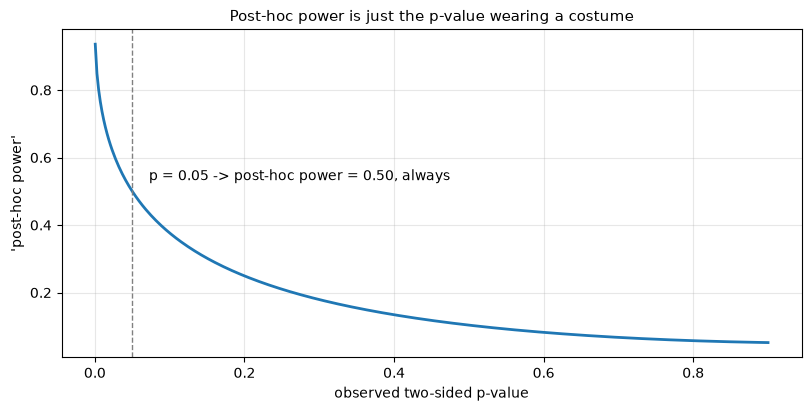

What to report instead: the DESIGN MDE (from the planned sizing) and the confidence interval - 'we could have detected X; the CI rules out lifts above Y'.


In [22]:
p_grid = np.linspace(0.0005, 0.9, 400)
z_obs = Z.ppf(1 - p_grid / 2)
posthoc = Z.cdf(z_obs - 1.96) + Z.cdf(-z_obs - 1.96)

fig, ax = plt.subplots(figsize=(8, 4))
ax.plot(p_grid, posthoc, lw=2)
ax.axvline(0.05, color="gray", ls="--", lw=1)
ax.annotate("p = 0.05 -> post-hoc power = 0.50, always", (0.05, 0.50),
            textcoords="offset points", xytext=(12, 8))
ax.set(xlabel="observed two-sided p-value", ylabel="'post-hoc power'",
       title="Post-hoc power is just the p-value wearing a costume")
plt.show()
print("What to report instead: the DESIGN MDE (from the planned sizing) and the "
      "confidence interval - 'we could have detected X; the CI rules out lifts above Y'.")

### Pitfall 2: using the pilot's observed effect as the MDE

The pilot was underpowered, so its significant estimate is Type-M inflated
(Section 7). Sizing the follow-up at "80% power for the effect we saw" then bakes the
exaggeration into the design. Simulation: true lift **+3% relative** on a 10% baseline;
a pilot with 5,000 users/arm; teams take significant positive pilots and size a
follow-up at nominal 80% power for the pilot's estimate.

In [23]:
P0_PILOT, DELTA_PILOT, N_PILOT = 0.10, 0.003, 5000
P1_PILOT = P0_PILOT + DELTA_PILOT
n_sims_p = 40_000

x = rng.binomial(N_PILOT, P0_PILOT, n_sims_p)
y = rng.binomial(N_PILOT, P1_PILOT, n_sims_p)
est = y / N_PILOT - x / N_PILOT
se = np.sqrt((x/N_PILOT)*(1-x/N_PILOT)/N_PILOT + (y/N_PILOT)*(1-y/N_PILOT)/N_PILOT)
pilot_power = (np.abs(est/se) > 1.96).mean()

winners = est[(est / se > 1.96)]  # significant AND positive -> 'promising pilot'
print(f"Pilot: n = {N_PILOT:,}/arm, true lift +3% rel -> pilot power = {pilot_power:.2%}")
print(f"Median significant-positive pilot estimate: {np.median(winners):.4f} "
      f"= {np.median(winners)/DELTA_PILOT:.1f}x the true effect {DELTA_PILOT}")

# Size follow-ups for 80% power at each winner's estimate, compute TRUE achieved power
var_sum = P0_PILOT*(1-P0_PILOT) + P1_PILOT*(1-P1_PILOT)
n_followup = (Z.ppf(0.975) + Z.ppf(0.8))**2 * var_sum / winners**2
se_followup = np.sqrt(var_sum / n_followup)
achieved = Z.cdf(DELTA_PILOT/se_followup - 1.96) + Z.cdf(-DELTA_PILOT/se_followup - 1.96)

print(f"Follow-up tests sized at nominal 80% for the pilot estimate:")
print(f"  median n/arm = {np.median(n_followup):,.0f} "
      f"(honest sizing would need {(Z.ppf(0.975)+Z.ppf(0.8))**2*var_sum/DELTA_PILOT**2:,.0f})")
print(f"  median TRUE power achieved = {np.median(achieved):.1%}; "
      f"share of follow-ups below 25% power = {(achieved < 0.25).mean():.0%}")
print("'We replicated at 80% power and it vanished' - no, you replicated at ~10% power.")

Pilot: n = 5,000/arm, true lift +3% rel -> pilot power = 8.12%
Median significant-positive pilot estimate: 0.0138 = 4.6x the true effect 0.003
Follow-up tests sized at nominal 80% for the pilot estimate:
  median n/arm = 7,517 (honest sizing would need 159,063)
  median TRUE power achieved = 9.3%; share of follow-ups below 25% power = 100%
'We replicated at 80% power and it vanished' - no, you replicated at ~10% power.


### Pitfalls recap (with pointers)

- **Diluted denominators** (Section 3): power on the triggered population; log exposure
  at the closest point to the change.
- **Wrong variance for the unit of analysis** (Section 6): if randomization is by
  cluster — or the metric is a ratio with a user-level denominator — user-level SEs are
  fiction. See [05_ratio_metrics_delta_method.ipynb](./05_ratio_metrics_delta_method.ipynb).
- **Peeking**: sizing assumes one look at the planned n. Continuous monitoring at
  $\alpha=0.05$ inflates false positives severalfold; sequential designs pay for looks
  with a larger maximum n — see [04_peeking_sequential.ipynb](./04_peeking_sequential.ipynb).
- **Post-hoc power / pilot-derived MDEs** (this section): both are the p-value or the
  winner's curse dressed up as design input.
- **Powering only the primary metric**: guardrails you'll act on (latency, churn,
  revenue) have their own — usually much larger — sample requirements. If a guardrail
  is underpowered, say so *before* launch.

## 10. Interview corner

**Q1. "How big should my A/B test be?"**
Strong answer works backwards: (1) primary metric and its baseline/variance from
historical data; (2) MDE = smallest lift worth acting on given eng cost and risk — a
business number, not a hope; (3) rule of 16 for the point answer, statsmodels for the
real one; (4) convert to weeks of traffic on the *triggered* population; (5) sanity
levers if infeasible — higher-baseline metric, CUPED, larger MDE, longer run. Bonus:
state the A/A false-positive check and SRM monitoring plan.

**Q2. "The PM wants results in one week."**
Don't say no — quantify. Invert the formula: with one week of traffic, here is the MDE
we can detect. If plausible effects are smaller, offer: (a) variance reduction (CUPED
often buys 30–50%); (b) a higher-rate proxy metric causally upstream of the target;
(c) relaxed $\alpha$ or one-sided testing *if* the decision is truly asymmetric and
pre-registered; (d) a group-sequential design with a planned early stop
([04_peeking_sequential.ipynb](./04_peeking_sequential.ipynb)); (e) ship-and-holdback:
launch, keep a small holdout to measure post-hoc. What you never offer: running the
underpowered test and "reading the direction" (Q4).

**Q3. "You only get 5% of traffic — what changes?"**
First clarify what "5%" means; the two readings differ by 4x. (a) *Treatment capped at
5%, the other 95% can serve as control*: variance ∝ $(1/0.05 + 1/0.95)/N \approx 21/N$
vs $4/N$ for full-traffic 50/50 — duration x~5.3 or MDE x~2.3 (and per Section 5, the
giant control is barely better than a 20% one). (b) *The experiment may only touch 5%
of traffic*, split 2.5/2.5: variance $= 80/N$ — duration x20 or MDE x~4.5.
Countermeasures: longer ramp, CUPED, a higher-baseline proxy metric, sequential
monitoring to stop early on large effects, or arguing for more traffic if the decision
justifies it. Also flag that a tiny treatment arm makes SRM and novelty effects harder
to detect quickly.

**Q4. "The test is underpowered but the lift is positive — can we ship directionally?"**
The point estimate from an underpowered test is close to worthless *conditionally*: if
it cleared significance, it is Type-M inflated (2–4x at 10–20% power) and has a real
chance of the wrong sign; if it didn't, the "direction" flips arm-to-arm with high
probability. If a decision must be made anyway, make the decision framework explicit —
priors from similar experiments, cost asymmetry of shipping vs not
([../06_bayesian_methods/01_bayesian_ab_testing.ipynb](../06_bayesian_methods/01_bayesian_ab_testing.ipynb))
— rather than laundering noise through a hypothesis test.

**Q5. "Your simulated power disagrees with the formula — which do you trust?"**
First validate the simulator on a case with a known answer (we did: two proportions).
If it passes, trust the simulation: the formula assumes independent units, normal
sampling distribution, the matching test, and one look. Each broken assumption
(clusters, heavy tails + small n, rank tests, peeking) is a reason the formula is the
wrong answer to the right question.

**Q6. "We can only randomize by city. Sketch the power math."**
Name the design effect: DEFF = 1 + (m−1)ρ; with thousands of users per city even
ρ ≈ 0.007 gives DEFF ≈ 20 — power is set by the number of *cities*. Then the fixes:
pair/stratify cities, pre-period covariate adjustment at the city level, synthetic
control for very few units; and the analysis must be at the randomization unit or use
cluster-robust SEs.

**Q7. "Where does the MDE come from in the first place?"**
From economics, not statistics: the lift that pays back the engineering, complexity,
and risk budget (an expected-value calculation), floored by what the org has
historically achieved — if your best features move the metric 2%, powering for 10% is
theater. Cite the distribution of past experiment effects if the org has one.

## 11. Key takeaways

- One formula runs the show: $n \approx 16\sigma^2/\delta^2$ per arm. Halving the MDE
  quadruples n; variance is the only lever you can engineer without changing the
  question.
- Solve for **MDE given traffic**, then argue about whether that MDE is decision-
  relevant. Deliver the answer in weeks, not observations.
- Power the **triggered** population. Dilution shrinks the effect linearly but the
  noise barely shrinks — analyzing all users can triple the traffic bill.
- `simulate_power()` = generator + the exact analysis + rejection count. Validate it on
  an analytic case, then trust it over formulas for zero-inflated metrics, rank tests,
  bootstrap tests, clusters, and unequal splits. The A/A run is a free pipeline audit.
- Test–effect pairing beats test choice: Mann–Whitney demolished the t-test on a
  payer-rate shift and was blind to a whale-side shift with the *same* ARPU impact.
- Unbalanced splits cost $0.25/(q(1-q))$ in total N — 90/10 ≈ 2.8x — and are still
  often right (risk, cost, shared controls). Control beyond ~4x treatment is wasted.
- Cluster randomization: DEFF = 1 + (m−1)ρ. Geo tests are powered by the number of
  geos; analyzing them at the user level produces mostly-false positives.
- Underpowered + significant = exaggerated (Type M) and possibly wrong-signed (Type S).
  Never size follow-ups on pilot estimates; never report post-hoc power.

## 12. Exercises

**Exercise 1.** A subscription product has ARPU \$5.00 with SD \$30. Traffic allows
200,000 eligible users/week into a 50/50 test. (a) Compute n/arm and duration for a +3%
relative MDE at 80% power. (b) The team has a pre-experiment covariate with
$\rho = 0.6$ (CUPED). How does the duration change? (c) The PM will only accept 3
weeks: what relative MDE does that buy, with and without CUPED?

**Exercise 2.** Using `simulate_power`, compare Welch's t on raw revenue vs Welch's t
on revenue **winsorized at the pooled 99th percentile**, for *both* Section 4
scenarios (A: +10% payer rate; B: +10% spend per payer; n = 5,000/arm), plus the null
for size. Before running it, predict which scenario winsorization helps — and note
what estimand it silently changes.

**Exercise 3.** Rescue the Section 6 geo experiment without new geos: each geo also has
a pre-period conversion rate (same geo effects, no treatment). Analyze post-period
rates with an OLS adjustment for the pre-period rate
(`post ~ treat + pre`) and estimate the power gain at the same +5% relative lift.

In [24]:
# --- Solution to Exercise 1 ---
mu_e, sd_e = 5.00, 30.0
weekly_arm = 200_000 // 2
z2 = (Z.ppf(0.975) + Z.ppf(0.8))**2  # ~7.85

# (a)
delta_e = 0.03 * mu_e
n_raw = 2 * z2 * sd_e**2 / delta_e**2
print(f"(a) n/arm = {n_raw:,.0f} -> {math.ceil(n_raw/weekly_arm)} weeks")

# (b) CUPED multiplies variance by (1 - rho^2)
n_cuped = n_raw * (1 - 0.6**2)
print(f"(b) with CUPED rho=0.6: n/arm = {n_cuped:,.0f} -> {math.ceil(n_cuped/weekly_arm)} weeks")

# (c) invert for MDE at a 3-week budget
n_3wk = 3 * weekly_arm
for label, var_mult in [("raw", 1.0), ("CUPED", 1 - 0.6**2)]:
    mde_abs = np.sqrt(2 * z2 * sd_e**2 * var_mult / n_3wk)
    print(f"(c) 3 weeks, {label:5s}: relative MDE = {mde_abs/mu_e:.1%}")
print("CUPED cuts the 7-week test to 5 weeks, or buys a ~20% smaller MDE at fixed time.")

(a) n/arm = 627,910 -> 7 weeks
(b) with CUPED rho=0.6: n/arm = 401,863 -> 5 weeks
(c) 3 weeks, raw  : relative MDE = 4.3%
(c) 3 weeks, CUPED: relative MDE = 3.5%
CUPED cuts the 7-week test to 5 weeks, or buys a ~20% smaller MDE at fixed time.


In [25]:
# --- Solution to Exercise 2 ---
def welch_winsorized(x, y, q=0.99):
    cap = np.quantile(np.concatenate([x, y]), q)  # pooled cap keeps the null symmetric
    return st.ttest_ind(np.minimum(x, cap), np.minimum(y, cap), equal_var=False).pvalue


for sc_name in ["null (A/A)", "A: +10% payer rate", "B: +10% spend/payer"]:
    pay, mu = scenarios[sc_name]
    draw = two_arm(revenue_sampler(PAY0, MU0), revenue_sampler(pay, mu), N_ARM_REV)
    pw_raw, lo_r, hi_r = simulate_power(draw, tests["Welch t (mean)"], n_sims=N_SIMS_REV, seed=11)
    pw_win, lo_w, hi_w = simulate_power(draw, welch_winsorized, n_sims=N_SIMS_REV, seed=11)
    print(f"{sc_name:22s}  Welch raw: {pw_raw:.2f} [{lo_r:.2f},{hi_r:.2f}]   "
          f"Welch winsorized p99: {pw_win:.2f} [{lo_w:.2f},{hi_w:.2f}]")
print("Winsorization is not a free lunch, and WHERE the effect lives decides its value:")
print(" - Scenario A (payer-rate shift): the effect touches all spend levels, the cap "
      "only removes whale noise -> a solid power gain at the same n.")
print(" - Scenario B (multiplicative spend shift): the effect is concentrated in the "
      "very tail the cap clips - effect and SD shrink together -> ~no power gain.")
print(" - Either way the estimand is now the CAPPED mean. Orgs that pre-register capped "
      "revenue as the decision metric are accepting that bias for the variance win.")

null (A/A)              Welch raw: 0.04 [0.02,0.08]   Welch winsorized p99: 0.04 [0.02,0.07]


A: +10% payer rate      Welch raw: 0.38 [0.32,0.44]   Welch winsorized p99: 0.51 [0.45,0.57]


B: +10% spend/payer     Welch raw: 0.31 [0.26,0.37]   Welch winsorized p99: 0.33 [0.27,0.39]
Winsorization is not a free lunch, and WHERE the effect lives decides its value:
 - Scenario A (payer-rate shift): the effect touches all spend levels, the cap only removes whale noise -> a solid power gain at the same n.
 - Scenario B (multiplicative spend shift): the effect is concentrated in the very tail the cap clips - effect and SD shrink together -> ~no power gain.
 - Either way the estimand is now the CAPPED mean. Orgs that pre-register capped revenue as the decision metric are accepting that bias for the variance win.


In [26]:
# --- Solution to Exercise 3 ---
def geo_experiment_with_pre(lift):
    def draw(rng):
        p_g = np.clip(rng.normal(BASE_P, GEO_SD, N_GEOS), 0.005, 0.6)
        treated = np.zeros(N_GEOS, dtype=bool)
        treated[rng.permutation(N_GEOS)[: N_GEOS // 2]] = True
        pre = rng.binomial(M_USERS, p_g) / M_USERS                    # pre-period, no treatment
        post = rng.binomial(M_USERS, np.where(treated, p_g * (1 + lift), p_g)) / M_USERS
        return post, pre, treated
    return draw


def adjusted_geo_test(post, pre, treated):
    X = sm.add_constant(np.column_stack([treated.astype(float), pre]))
    fit = sm.OLS(post, X).fit()
    return fit.pvalues[1]


def unadjusted_geo_test(post, pre, treated):
    return st.ttest_ind(post[treated], post[~treated], equal_var=False).pvalue


pw_unadj, lo_u, hi_u = simulate_power(geo_experiment_with_pre(GEO_LIFT), unadjusted_geo_test,
                                      n_sims=600, seed=51)
pw_adj, lo_a, hi_a = simulate_power(geo_experiment_with_pre(GEO_LIFT), adjusted_geo_test,
                                    n_sims=600, seed=51)
rho_geo = GEO_SD**2 / (GEO_SD**2 + BASE_P * (1 - BASE_P) / M_USERS)
print(f"Geo-level pre/post correlation ~ {np.sqrt(rho_geo):.2f} "
      f"-> residual variance x{1-rho_geo:.2f}")
print(f"power, unadjusted geo t-test : {pw_unadj:.2f} [{lo_u:.2f}, {hi_u:.2f}]")
print(f"power, pre-period adjusted   : {pw_adj:.2f} [{lo_a:.2f}, {hi_a:.2f}]")
print("Cluster-level covariate adjustment (CUPED's geo cousin) recovers much of the "
      "power the design effect destroyed - same trick as 03_variance_reduction_cuped.ipynb, "
      "one level up.")

Geo-level pre/post correlation ~ 0.98 -> residual variance x0.05
power, unadjusted geo t-test : 0.09 [0.07, 0.12]
power, pre-period adjusted   : 0.52 [0.48, 0.56]
Cluster-level covariate adjustment (CUPED's geo cousin) recovers much of the power the design effect destroyed - same trick as 03_variance_reduction_cuped.ipynb, one level up.
